# Temporal Shapley attribution on GA4 ecommerce journeys

Weekly epoch-by-epoch Shapley attribution over the GA4 extract, with the
per-epoch normalization state and the data-driven epoch recommendation workflow.

In [1]:
# In Colab, install the package first:
# %pip install "do-attribution[viz,temporal]"
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Sum of Shapley values")
warnings.filterwarnings("ignore", message="Total removal effect is 0")
pd.set_option("display.width", 160)

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## Load, summarize, and parse the timestamp column

`anchor_timestamp` gives every journey exactly one anchor. The temporal
classes assign each complete journey to one epoch by that anchor and run an
independent static fit inside every epoch — no smoothing, no state shared
across boundaries. The GA4 sample covers November 2020 through January 2021, providing
daily timestamps for calendar-based and data-driven epoch analysis.

In [2]:
journeys = pd.read_csv("ga4_attribution_journeys.csv")

required = {"path", "conversion", "anchor_timestamp"}
assert required.issubset(journeys.columns), f"missing columns: {required - set(journeys.columns)}"
assert journeys["path"].notna().all() and (journeys["path"].str.len() > 0).all()
assert journeys["conversion"].isin([0, 1]).all()

paths = journeys["path"]
conversions = journeys["conversion"]
timestamps = pd.to_datetime(journeys["anchor_timestamp"]).dt.tz_localize(None)

channels = sorted({channel for path in paths for channel in path.split(" > ")})
path_lengths = paths.str.count(" > ") + 1
print(f"journeys        : {len(journeys):,}")
print(f"conversions     : {conversions.sum():,}  (rate {conversions.mean():.4f})")
print(f"date range      : {timestamps.min().date()} to {timestamps.max().date()}")
print(f"channels ({len(channels)})    : {', '.join(channels)}")
print(f"path length     : mean {path_lengths.mean():.2f}, max {path_lengths.max()}; "
      f"{(path_lengths > 1).mean():.1%} of journeys are multi-touch")
journeys.head()

journeys        : 272,792
conversions     : 4,848  (rate 0.0178)
date range      : 2020-11-01 to 2021-01-31
channels (8)    : Affiliate, Direct, Email, Organic Search, Organic Social, Other, Paid Search, Referral
path length     : mean 1.17, max 12; 11.4% of journeys are multi-touch


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12T04:11:17Z,2020-12-12T04:11:17Z,1,1,0
1,journey_0000002,Direct,0,2021-01-07T18:35:34Z,2021-01-07T18:35:34Z,1,1,0
2,journey_0000003,Direct,0,2021-01-20T11:04:59Z,2021-01-20T11:04:59Z,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04T09:21:11Z,2020-11-04T13:43:30Z,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11T17:25:12Z,2020-12-11T17:25:12Z,1,1,0


## Fit calendar-based weekly epochs

In [3]:
from do_attribution import TemporalShapleyAttribution

temporal_shapley = TemporalShapleyAttribution(
    freq="W",
    min_samples_per_epoch=30,
)
temporal_shapley.fit(paths, timestamps, conversions)
print(f"epochs fitted: {len(temporal_shapley.epochs)} "
      f"({temporal_shapley.epochs[0]} ... {temporal_shapley.epochs[-1]})")
assigned = int(temporal_shapley.get_epoch_summary()["n_paths"].sum())
print(f"journeys assigned to an epoch: {assigned:,} of {len(paths):,}")

epochs fitted: 14 (2020-10-26/2020-11-01 ... 2021-01-25/2021-01-31)


journeys assigned to an epoch: 272,792 of 272,792


## Epoch normalization results

In [4]:
attribution_matrix = temporal_shapley.get_attribution_matrix()
normalization_state = pd.DataFrame.from_dict({
    str(epoch): {
        "status": result.get("normalization_status", "available"),
        "reason": result.get("normalization_reason"),
    }
    for epoch, result in temporal_shapley.epoch_results.items()
}, orient="index")
display(normalization_state)
if attribution_matrix.empty:
    print("No epoch produced a valid normalized attribution vector; raw values remain available below.")
else:
    display(attribution_matrix.round(4))

,status,reason
2020-10-26/2020-11-01,available,None
2020-11-02/2020-11-08,available,None
2020-11-09/2020-11-15,available,None
2020-11-16/2020-11-22,available,None
2020-11-23/2020-11-29,available,None
2020-11-30/2020-12-06,available,None
2020-12-07/2020-12-13,available,None
2020-12-14/2020-12-20,available,None
2020-12-21/2020-12-27,available,None
2020-12-28/2021-01-03,available,None


,Affiliate,Direct,Email,Organic Search,Organic Social,Other,Paid Search,Referral
2020-10-26/2020-11-01,0.0000,0.1154,NaN,0.3462,NaN,0.0769,0.0000,0.4615
2020-11-02/2020-11-08,0.0000,0.1024,0.0000,0.3755,0.0000,0.0723,0.0167,0.4331
2020-11-09/2020-11-15,0.0000,0.0687,NaN,0.4255,0.0000,0.0633,0.0073,0.4352
2020-11-16/2020-11-22,0.0000,0.0907,NaN,0.4416,0.0027,0.0472,0.0131,0.4046
2020-11-23/2020-11-29,0.0000,0.0979,0.0084,0.4018,0.0000,0.0762,0.0097,0.4060
2020-11-30/2020-12-06,0.0000,0.0965,0.0071,0.3909,0.0008,0.0735,0.0171,0.4140
2020-12-07/2020-12-13,0.0000,0.1106,0.0047,0.3725,0.0026,0.0675,0.0146,0.4275
2020-12-14/2020-12-20,0.0000,0.1158,0.0068,0.3900,0.0018,0.0735,0.0178,0.3944
2020-12-21/2020-12-27,0.0000,0.1155,0.0036,0.3423,0.0000,0.0712,0.0050,0.4624
2020-12-28/2021-01-03,0.0024,0.0990,0.0000,0.3853,0.0000,0.0707,0.0308,0.4118


## Channel trends

In [5]:
display(attribution_matrix[["Referral", "Organic Search"]].round(4))
raw_shapley_matrix = temporal_shapley.get_shapley_values_matrix()
display(raw_shapley_matrix[["Referral", "Organic Search"]].round(2))
weekly_conversions = temporal_shapley.get_epoch_summary()["n_conversions"].to_numpy()
largest_gap = abs(raw_shapley_matrix.sum(axis=1).to_numpy() - weekly_conversions).max()
print("Raw Shapley values are conversions credited to a channel in that week; "
      f"largest gap between a week's raw total and its conversions: {largest_gap:.1e}")

,Referral,Organic Search
2020-10-26/2020-11-01,0.4615,0.3462
2020-11-02/2020-11-08,0.4331,0.3755
2020-11-09/2020-11-15,0.4352,0.4255
2020-11-16/2020-11-22,0.4046,0.4416
2020-11-23/2020-11-29,0.4060,0.4018
2020-11-30/2020-12-06,0.4140,0.3909
2020-12-07/2020-12-13,0.4275,0.3725
2020-12-14/2020-12-20,0.3944,0.3900
2020-12-21/2020-12-27,0.4624,0.3423
2020-12-28/2021-01-03,0.4118,0.3853


,Referral,Organic Search
2020-10-26/2020-11-01,6.00,4.50
2020-11-02/2020-11-08,107.83,93.50
2020-11-09/2020-11-15,148.42,145.08
2020-11-16/2020-11-22,151.33,165.17
2020-11-23/2020-11-29,209.08,206.92
2020-11-30/2020-12-06,244.28,230.62
2020-12-07/2020-12-13,330.03,287.53
2020-12-14/2020-12-20,216.50,214.08
2020-12-21/2020-12-27,107.75,79.75
2020-12-28/2021-01-03,56.83,53.17


Raw Shapley values are conversions credited to a channel in that week; largest gap between a week's raw total and its conversions: 1.1e-13


## Epoch summaries and sample-size diagnostics

In [6]:
display(temporal_shapley.get_epoch_summary())
thin_cells = temporal_shapley.get_channel_epoch_sample_sizes()
print(f"channel-by-epoch cells flagged thin: {int(thin_cells['thin'].sum())} of {len(thin_cells)}")

,n_paths,n_conversions,n_channels,total_shapley,sufficient_data,n_thin_channels
epoch,,,,,,
2020-10-26/2020-11-01,2033,13,6,13.0,True,1
2020-11-02/2020-11-08,17286,249,8,249.0,True,1
2020-11-09/2020-11-15,15224,341,7,341.0,True,0
2020-11-16/2020-11-22,17511,374,7,374.0,True,0
2020-11-23/2020-11-29,19910,515,8,515.0,True,0
2020-11-30/2020-12-06,22140,590,8,590.0,True,0
2020-12-07/2020-12-13,29413,772,8,772.0,True,0
2020-12-14/2020-12-20,25708,549,8,549.0,True,0
2020-12-21/2020-12-27,17947,233,8,233.0,True,1


channel-by-epoch cells flagged thin: 7 of 107


## Temporal model summary (plain-text report)

In [7]:
print(temporal_shapley.summary())

Temporal Attribution Summary
Model: TemporalShapleyAttribution
Epoch source: calendar:W
Timeline: 2020-10-26 to 2021-02-01
Boundaries: 2020-10-26 | 2020-11-02 | 2020-11-09 | 2020-11-16 | 2020-11-23 | 2020-11-30 | 2020-12-07 | 2020-12-14 | 2020-12-21 | 2020-12-28 | 2021-01-04 | 2021-01-11 | 2021-01-18 | 2021-01-25 | 2021-02-01
Sample floor: 30 paths
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Epochs
+-----------------------+------------+------------+-------+-------------+---------+--------+-------------------------------------------------------+
| Epoch                 | Start      | End        | Paths | Conversions | Conv. % | Health | Top channels                                          |
+-----------------------+------------+------------+-------+-------------+---------+--------+-------------------------------------------------------+
| 2020-10-26/2020-11-01 | 2020-10-26 | 2020-11-02 | 2033  | 13          | 0.64%   | PASS   | Referral 46.15%, Organic Search 34.62%

## Flat DataFrame export

In [8]:
tables = temporal_shapley.to_dataframes()
print("keys:", list(tables))
display(tables["attribution"].head(10))
display(tables["shapley_values"].head(10))
display(tables["epoch_summary"])

keys: ['attribution', 'shapley_values', 'epoch_summary', 'channel_epoch_sample_sizes']


,epoch,channel,attribution
0,2020-10-26/2020-11-01,Affiliate,0.000000
1,2020-10-26/2020-11-01,Direct,0.115385
2,2020-10-26/2020-11-01,Email,NaN
3,2020-10-26/2020-11-01,Organic Search,0.346154
4,2020-10-26/2020-11-01,Organic Social,NaN
5,2020-10-26/2020-11-01,Other,0.076923
6,2020-10-26/2020-11-01,Paid Search,0.000000
7,2020-10-26/2020-11-01,Referral,0.461538
8,2020-11-02/2020-11-08,Affiliate,0.000000
9,2020-11-02/2020-11-08,Direct,0.102410


,epoch,channel,shapley_value
0,2020-10-26/2020-11-01,Affiliate,0.0
1,2020-10-26/2020-11-01,Direct,1.5
2,2020-10-26/2020-11-01,Email,NaN
3,2020-10-26/2020-11-01,Organic Search,4.5
4,2020-10-26/2020-11-01,Organic Social,NaN
5,2020-10-26/2020-11-01,Other,1.0
6,2020-10-26/2020-11-01,Paid Search,0.0
7,2020-10-26/2020-11-01,Referral,6.0
8,2020-11-02/2020-11-08,Affiliate,0.0
9,2020-11-02/2020-11-08,Direct,25.5


,epoch,n_paths,n_conversions,n_channels,total_shapley,sufficient_data,n_thin_channels
0,2020-10-26/2020-11-01,2033,13,6,13.0,True,1
1,2020-11-02/2020-11-08,17286,249,8,249.0,True,1
2,2020-11-09/2020-11-15,15224,341,7,341.0,True,0
3,2020-11-16/2020-11-22,17511,374,7,374.0,True,0
4,2020-11-23/2020-11-29,19910,515,8,515.0,True,0
5,2020-11-30/2020-12-06,22140,590,8,590.0,True,0
6,2020-12-07/2020-12-13,29413,772,8,772.0,True,0
7,2020-12-14/2020-12-20,25708,549,8,549.0,True,0
8,2020-12-21/2020-12-27,17947,233,8,233.0,True,1
9,2020-12-28/2021-01-03,17033,138,8,138.0,True,1


## Weekly attribution trends

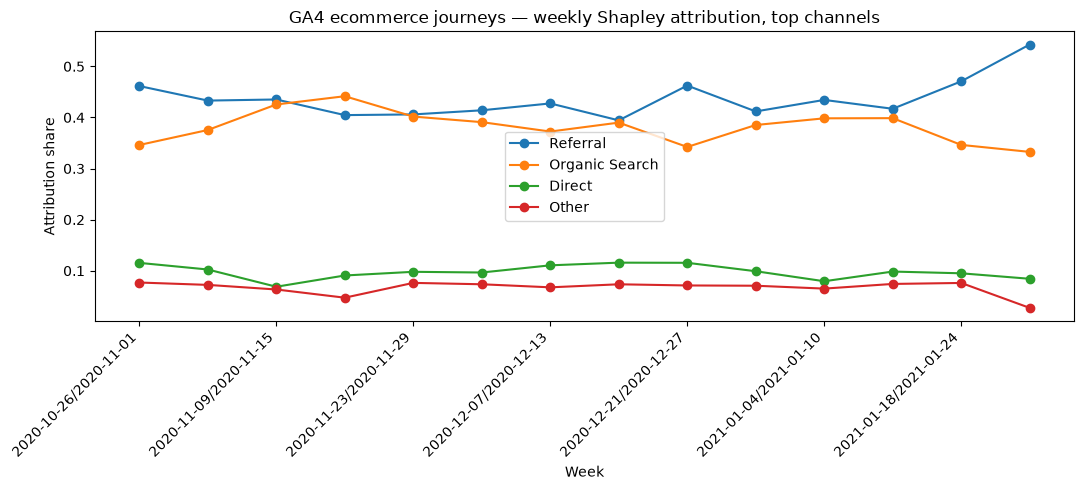

In [9]:
top_channels = attribution_matrix.mean().sort_values(ascending=False).head(4).index
trend_frame = attribution_matrix[top_channels]
trend_frame.index = [str(epoch) for epoch in trend_frame.index]
ax = trend_frame.plot(marker="o", figsize=(11, 5))
ax.set_title("GA4 ecommerce journeys — weekly Shapley attribution, top channels")
ax.set_ylabel("Attribution share")
ax.set_xlabel("Week")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.gcf().savefig(IMAGES / "ga4_temporal_shapley.png", dpi=110, bbox_inches="tight")
plt.show()

## Data-driven epoch recommendation

The conversion-rate signal drives the recommendation
(`transition_drift` is Markov-only and is rejected by the Shapley class).

In [10]:
recommended_shapley = TemporalShapleyAttribution(min_samples_per_epoch=30)
recommended_shapley.fit_recommended(paths, conversions, timestamps)
recommendation = recommended_shapley.epoch_recommendation
print("recommended boundaries:", [str(b.date()) for b in recommendation.boundaries])
print(recommended_shapley.summary())

recommended boundaries: ['2020-11-01', '2020-11-15', '2020-12-12', '2020-12-30', '2021-02-01']
Temporal Attribution Summary
Model: TemporalShapleyAttribution
Epoch source: recommended:conversion_rate
Timeline: 2020-11-01 to 2021-02-01
Boundaries: 2020-11-01 | 2020-11-15 | 2020-12-12 | 2020-12-30 | 2021-02-01
Sample floor: 30 paths
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Epochs
+-------+------------+------------+--------+-------------+---------+--------+-------------------------------------------------------+
| Epoch | Start      | End        | Paths  | Conversions | Conv. % | Health | Top channels                                          |
+-------+------------+------------+--------+-------------+---------+--------+-------------------------------------------------------+
| E1    | 2020-11-01 | 2020-11-15 | 32926  | 580         | 1.76%   | PASS   | Referral 43.49%, Organic Search 40.10%, Direct 8.61%  |
| E2    | 2020-11-15 | 2020-12-12 | 84231  | 2111        | 2

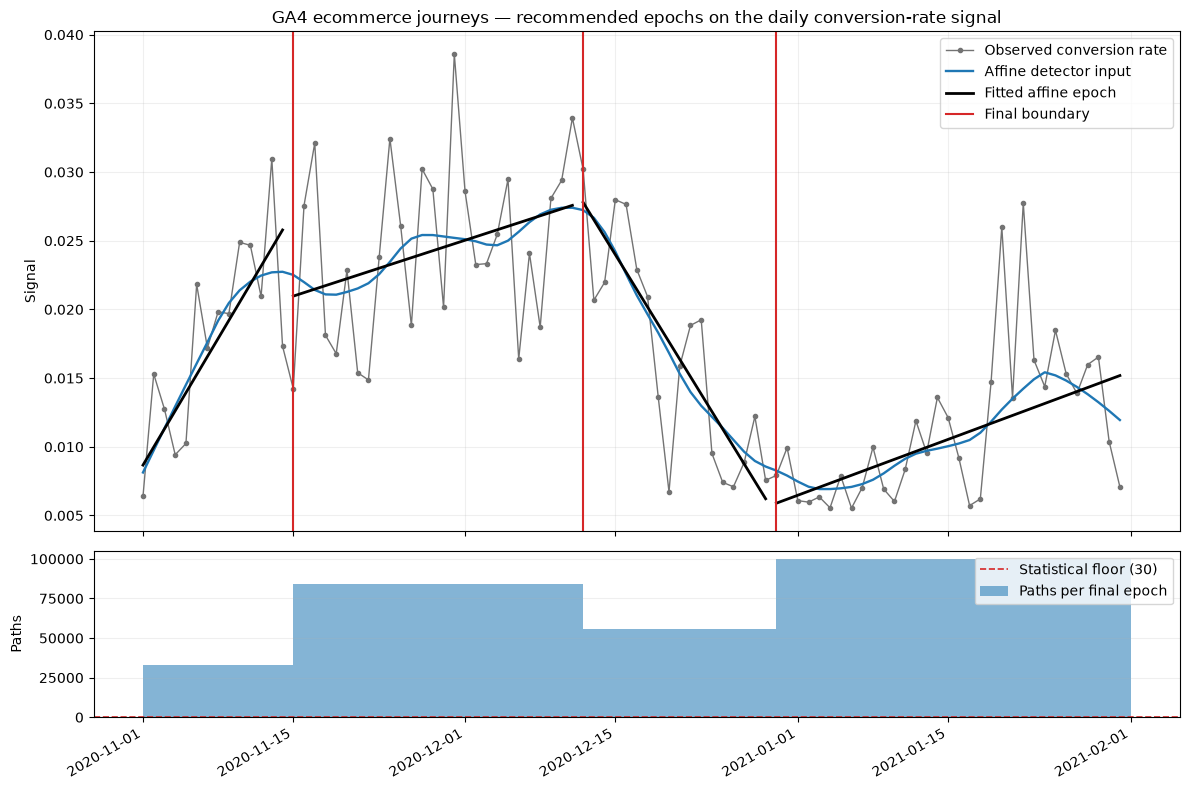

In [11]:
from do_attribution.visualization import plot_epoch_recommendation

fig = plot_epoch_recommendation(
    recommendation,
    title="GA4 ecommerce journeys — recommended epochs on the daily conversion-rate signal",
)
fig.savefig(IMAGES / "ga4_shapley_epoch_recommendation.png", dpi=110, bbox_inches="tight")
plt.show()